In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Interband contributions

First, we compute the interband part of permittivity :
$$ \varepsilon(\lambda) = \varepsilon^D(\lambda) + \varepsilon^{ib}(\lambda) - 1$$
$$\varepsilon^{ib}(\lambda) = 1 + (\varepsilon(\lambda) - \varepsilon^D(\lambda))$$

## Compute eps2 for each band

$$\Delta \varepsilon_2^{ib} = -\sum_m \frac{\partial \varepsilon^{ib}_{2, m}}{\partial \lambda} \Delta \lambda_{ib,m}$$

$$\Delta \lambda_{ib,m} = \frac{\partial \lambda_{ib,m}}{\partial V} \Delta V = \left( \frac{\partial \lambda_{ib,m}}{\partial T
} \cdot \frac{\partial T}{\partial V
}\right) \Delta V = \frac{\partial \lambda_{ib,m}}{\partial T} \frac{dV}{3\alpha V}$$

### Get the interpolated values of interband dielectric function fitted on experimental data

In [2]:
# Get the eps2 extracted from Jhonson christy
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Interbande_fits'

dir_root += r'\Stoll_2014'
#dir_root += r'\Magnozzi_25C'

fname = 'eps_2_fit.csv'

Data_eps2 = get_eps2_ib(dir_root, fname)

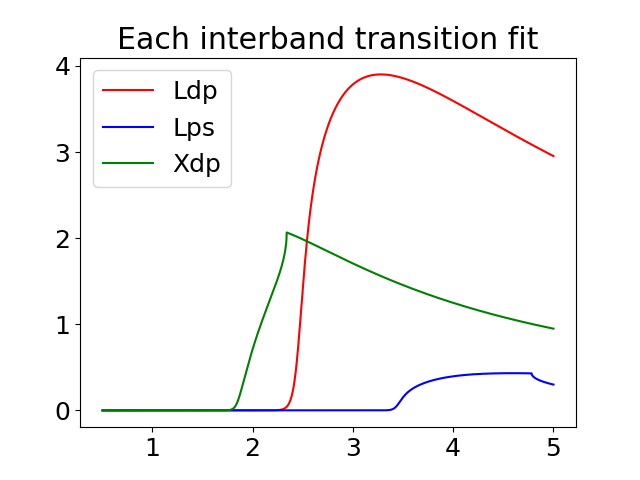

In [3]:
fig, ax = plt.subplots()

ax.plot(Data_eps2['eV'], Data_eps2['eps2_Ldp'], label = 'Ldp', color='red')
ax.plot(Data_eps2['eV'], Data_eps2['eps2_Lps'], label = 'Lps', color='blue')
ax.plot(Data_eps2['eV'], Data_eps2['eps2_Xdp'], label = 'Xdp', color='green')

ax.set_title('Each interband transition fit')
ax.legend()

### Compute the rigid derivatives of permittivity  $\frac{\partial \varepsilon^{ib}_{2, m}}{\partial \lambda}$

In [4]:
sigma = 20 #smoothing coeff for X transition
Energy = np.linspace(1, 4, 20000)
Permittivity_variations = {}

Permittivity_variations['ib'] = {}
Permittivity_variations['ib']['Energy'] = Energy
Permittivity_variations['ib']['lambda'] = 1240/Energy
Permittivity_variations['ib']['eps2_interp'] = {}
Permittivity_variations['ib']['eps2_interp']['Ldp'] = sc.interpolate.interp1d(Data_eps2['eV'], Data_eps2['eps2_Ldp'], fill_value=0, kind='cubic', bounds_error=False)
Permittivity_variations['ib']['eps2_interp']['Lps'] = sc.interpolate.interp1d(Data_eps2['eV'], Data_eps2['eps2_Lps'], fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['eps2_interp']['Xdp'] = sc.interpolate.interp1d(Data_eps2['eV'], sc.ndimage.gaussian_filter1d(Data_eps2['eps2_Xdp'],sigma=sigma), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['eps2_interp']['Xdp_no_smoothing'] = sc.interpolate.interp1d(Data_eps2['eV'], Data_eps2['eps2_Xdp'], fill_value=0, kind='quadratic', bounds_error=False)



Permittivity_variations['ib']['deps2/deV'] = {}
Permittivity_variations['ib']['deps2/deV']['Ldp'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_variations['ib']['eps2_interp']['Ldp'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['deps2/deV']['Lps'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_variations['ib']['eps2_interp']['Lps'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['deps2/deV']['Xdp'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_variations['ib']['eps2_interp']['Xdp'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['deps2/deV']['Xdp_no_smoothing'] = sc.interpolate.interp1d(Energy, np.gradient(Permittivity_variations['ib']['eps2_interp']['Xdp_no_smoothing'](Energy) , Energy[1]-Energy[0]), fill_value=0, kind='quadratic', bounds_error=False)


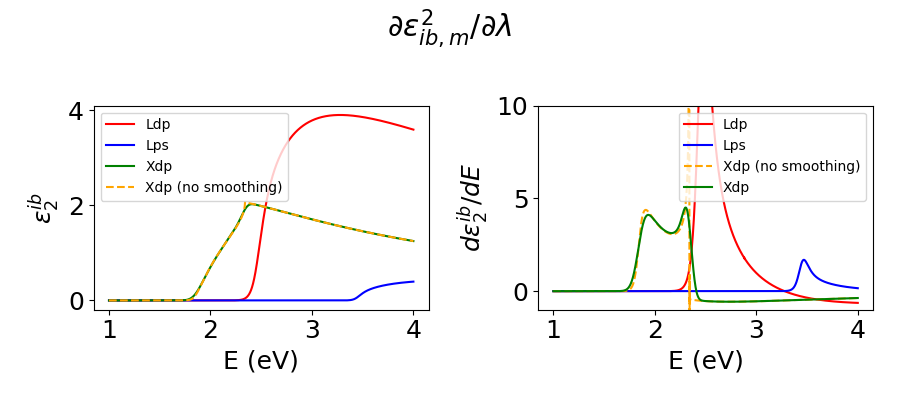

In [5]:

fig, ax = plt.subplots(ncols=2, figsize = (9,4))

ax[0].plot(Energy, Permittivity_variations['ib']['eps2_interp']['Ldp'](Energy), color='red', label='Ldp')
ax[0].plot(Energy, Permittivity_variations['ib']['eps2_interp']['Lps'](Energy), color='blue', label='Lps')
ax[0].plot(Energy, Permittivity_variations['ib']['eps2_interp']['Xdp'](Energy), color='green', label='Xdp')
ax[0].plot(Energy, Permittivity_variations['ib']['eps2_interp']['Xdp_no_smoothing'](Energy), color='orange', linestyle='--', label='Xdp (no smoothing)')
ax[0].legend(fontsize=10)
ax[0].set_ylabel(r'$\varepsilon_2^{ib}$')
ax[0].set_xlabel('E (eV)')

ax[1].plot(Energy, Permittivity_variations['ib']['deps2/deV']['Ldp'](Energy), color='red', label='Ldp')
ax[1].plot(Energy, Permittivity_variations['ib']['deps2/deV']['Lps'](Energy), color='blue', label='Lps')
ax[1].plot(Energy, Permittivity_variations['ib']['deps2/deV']['Xdp_no_smoothing'](Energy), color='orange', linestyle='--', label='Xdp (no smoothing)')
ax[1].plot(Energy, Permittivity_variations['ib']['deps2/deV']['Xdp'](Energy), color='green', label='Xdp')
ax[1].legend(fontsize=10)
ax[1].set_ylabel(r'$d\varepsilon_2^{ib}/dE$')
ax[1].set_xlabel('E (eV)')
ax[1].set_ylim((-1, 10))

plt.suptitle(r'$\partial \varepsilon^2_{ib, m} / \partial \lambda$')
plt.tight_layout()

### Deduce the profile of eps1ib

In [6]:

W = Energy/sc.constants.hbar

Delta_eps1_ib_Ldp = elli.kkr.kkr.im2re(Permittivity_variations['ib']['deps2/deV']['Ldp'](Energy), W)
Delta_eps1_ib_Lps = elli.kkr.kkr.im2re(Permittivity_variations['ib']['deps2/deV']['Lps'](Energy), W)
Delta_eps1_ib_Xdp = elli.kkr.kkr.im2re(Permittivity_variations['ib']['deps2/deV']['Xdp'](Energy), W)
Delta_eps1_ib_tot = elli.kkr.kkr.im2re(Permittivity_variations['ib']['deps2/deV']['Xdp'](Energy) + Permittivity_variations['ib']['deps2/deV']['Lps'](Energy) + Permittivity_variations['ib']['deps2/deV']['Ldp'](Energy), W)


Permittivity_variations['ib']['deps1/deV'] = {}
Permittivity_variations['ib']['deps1/deV']['Ldp'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Ldp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['deps1/deV']['Lps'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Lps, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['deps1/deV']['Xdp'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Xdp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['deps1/deV']['tot'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_tot, fill_value=0, kind='quadratic', bounds_error=False)

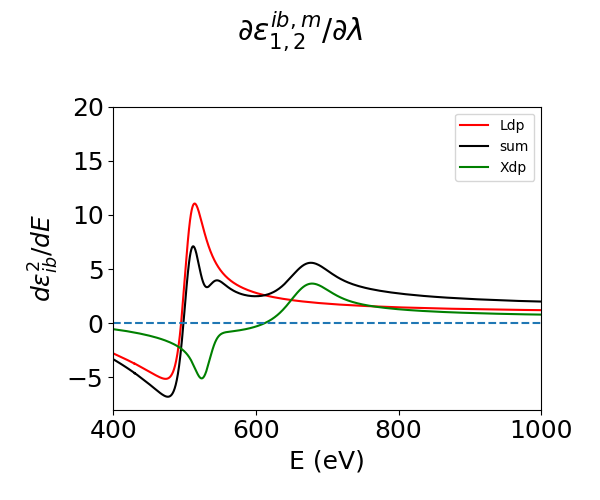

In [13]:
fig, ax = plt.subplots(figsize = (6,5))

ax.plot(1240/Energy, Permittivity_variations['ib']['deps1/deV']['Ldp'](Energy), color='red', label='Ldp')
ax.plot(1240/Energy,Permittivity_variations['ib']['deps1/deV']['Ldp'](Energy) +Permittivity_variations['ib']['deps1/deV']['Xdp'](Energy) , color='black', label='sum')
ax.plot(1240/Energy, Permittivity_variations['ib']['deps1/deV']['Xdp'](Energy), color='green', label='Xdp')
ax.axhline(0, linestyle='--')
ax.legend(fontsize=10)
ax.set_ylabel(r'$d\varepsilon^2_{ib}/dE$')
ax.set_xlabel('E (eV)')


ax.set_xlim((400, 1000))
ax.set_ylim((-8, 20))

plt.suptitle(r'$\partial \varepsilon_{1,2}^{ib, m} / \partial \lambda$')
plt.tight_layout()

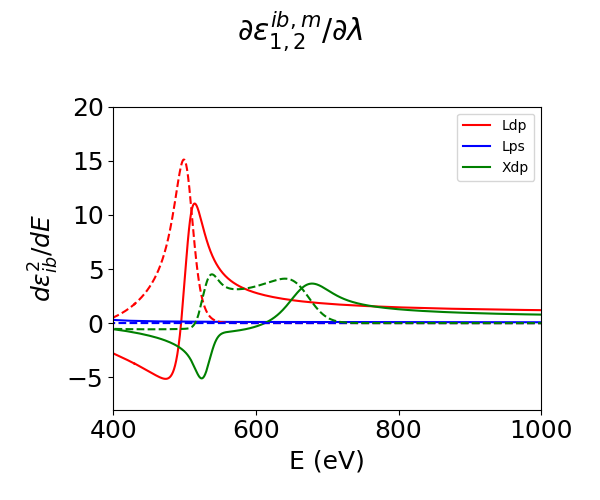

In [8]:
fig, ax = plt.subplots(figsize = (6,5))

ax.plot(1240/Energy, Permittivity_variations['ib']['deps1/deV']['Ldp'](Energy), color='red', label='Ldp')
ax.plot(1240/Energy, Permittivity_variations['ib']['deps1/deV']['Lps'](Energy), color='blue', label='Lps')
ax.plot(1240/Energy, Permittivity_variations['ib']['deps1/deV']['Xdp'](Energy), color='green', label='Xdp')


ax.plot(1240/Energy, Permittivity_variations['ib']['deps2/deV']['Ldp'](Energy),linestyle='--', color='red')
ax.plot(1240/Energy, Permittivity_variations['ib']['deps2/deV']['Lps'](Energy),linestyle='--', color='blue')
ax.plot(1240/Energy, Permittivity_variations['ib']['deps2/deV']['Xdp'](Energy),linestyle='--', color='green')
ax.legend(fontsize=10)
ax.set_ylabel(r'$d\varepsilon^2_{ib}/dE$')
ax.set_xlabel('E (eV)')


ax.set_xlim((400, 1000))
ax.set_ylim((-8, 20))

plt.suptitle(r'$\partial \varepsilon_{1,2}^{ib, m} / \partial \lambda$')
plt.tight_layout()

## Estimate the resulting change in permittivity 

$$\Delta \lambda_{ib,m} = \frac{\partial \lambda_{ib,m}}{\partial V} \Delta V = \left( \frac{\partial \lambda_{ib,m}}{\partial T
} \cdot \frac{\partial T}{\partial V
}\right) \Delta V = \frac{\partial \lambda_{ib,m}}{\partial T} \frac{dV}{3\alpha V}$$

In [9]:
alpha = 1.42e-5 #in K-1

#Valeurs Stoll 2014
dwp_dT_Ldp = -1.7e-4 # for the d->p (L) transition, in eV/K
dwp_dT_Xdp = -3.2e-4 # for the d->p (X) transition, in eV/K
dwp_dT_Lps = 0 # for the p->s (L) transition, in eV/K

# Winsemius 1976 : valeurs à 300 K
# dwp_dT_Ldp = -3e-4 # for the d->p (L) transition, in eV/K
# dwp_dT_Xdp = 0 # for the d->p (X) transition, in eV/K
# dwp_dT_Lps = 0 # for the p->s (L) transition, in eV/K

#dwp_dT_Xdp = 0 # for the d->p (X) transition, in eV/K
#dwp_dT_Xdp = 0 # for the d->p (X) transition, in eV/K
# dwp_dT_Lps = 0  



Delta_eps2_ib_Ldp = - dwp_dT_Ldp * 1/(3*alpha) * Permittivity_variations['ib']['deps2/deV']['Ldp'](Energy)
Delta_eps2_ib_Lps = - dwp_dT_Lps * 1/(3*alpha) * Permittivity_variations['ib']['deps2/deV']['Lps'](Energy)
Delta_eps2_ib_Xdp = - dwp_dT_Xdp * 1/(3*alpha) * Permittivity_variations['ib']['deps2/deV']['Xdp'](Energy)
Delta_eps2_ib_total = Delta_eps2_ib_Xdp + Delta_eps2_ib_Ldp + Delta_eps2_ib_Lps
Permittivity_variations['ib']['delta_eps2'] = {}
Permittivity_variations['ib']['delta_eps2']['Ldp'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_Ldp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['delta_eps2']['Lps'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_Lps, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['delta_eps2']['Xdp'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_Xdp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['delta_eps2']['total'] = sc.interpolate.interp1d(Energy, Delta_eps2_ib_total, fill_value=0, kind='quadratic', bounds_error=False)


Delta_eps1_ib_Ldp = - dwp_dT_Ldp * 1/(3*alpha) * Permittivity_variations['ib']['deps1/deV']['Ldp'](Energy)
Delta_eps1_ib_Lps = - dwp_dT_Lps * 1/(3*alpha) * Permittivity_variations['ib']['deps1/deV']['Lps'](Energy)
Delta_eps1_ib_Xdp = - dwp_dT_Xdp * 1/(3*alpha) * Permittivity_variations['ib']['deps1/deV']['Xdp'](Energy)
Delta_eps1_ib_total = Delta_eps1_ib_Xdp + Delta_eps1_ib_Ldp + Delta_eps1_ib_Lps
Permittivity_variations['ib']['delta_eps1'] = {}
Permittivity_variations['ib']['delta_eps1']['Ldp'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Ldp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['delta_eps1']['Lps'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Lps, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['delta_eps1']['Xdp'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_Xdp, fill_value=0, kind='quadratic', bounds_error=False)
Permittivity_variations['ib']['delta_eps1']['total'] = sc.interpolate.interp1d(Energy, Delta_eps1_ib_total, fill_value=0, kind='quadratic', bounds_error=False)



Delta_eps1_ib_tot = elli.kkr.kkr.im2re(Delta_eps2_ib_total, W)
f_eps1 = sc.interpolate.interp1d(Energy, Delta_eps1_ib_total, fill_value=0, kind='quadratic', bounds_error=False)


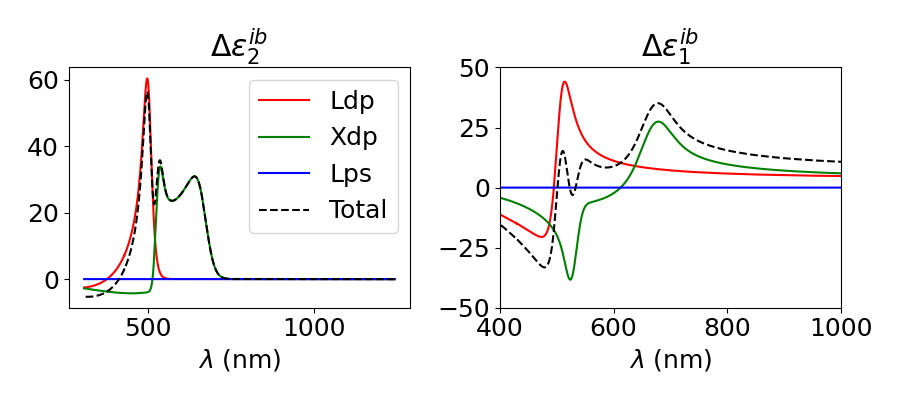

In [10]:
fig,ax = plt.subplots(ncols=2, figsize=(9,4))

ax[0].plot(1240/Energy, Permittivity_variations['ib']['delta_eps2']['Ldp'](Energy), color='red', label = 'Ldp')
ax[0].plot(1240/Energy, Permittivity_variations['ib']['delta_eps2']['Xdp'](Energy), color='green', label = 'Xdp')
ax[0].plot(1240/Energy, Permittivity_variations['ib']['delta_eps2']['Lps'](Energy), color='blue', label = 'Lps')
ax[0].plot(1240/Energy, Permittivity_variations['ib']['delta_eps2']['total'](Energy), color='black', linestyle = '--', label = 'Total')


ax[0].set_title(r'$\Delta \varepsilon_2^{ib}$')

ax[0].set_xlabel(r'$\lambda$ (nm)')
ax[0].legend()


ax[1].plot(1240/Energy, Permittivity_variations['ib']['delta_eps1']['Ldp'](Energy), color='red', label = 'Ldp')
ax[1].plot(1240/Energy, Permittivity_variations['ib']['delta_eps1']['Xdp'](Energy), color='green', label = 'Xdp')
ax[1].plot(1240/Energy, Permittivity_variations['ib']['delta_eps1']['Lps'](Energy), color='blue', label = 'Lps')
ax[1].plot(1240/Energy, Permittivity_variations['ib']['delta_eps1']['total'](Energy), color='black', linestyle = '--', label = 'Total')

ax[1].set_title(r'$\Delta \varepsilon_1^{ib}$')

ax[1].set_xlabel(r'$\lambda$ (nm)')

ax[1].set_xlim((400, 1000))
ax[1].set_ylim((-50, 50))

plt.tight_layout()

In [11]:
print(((2*np.pi*1.38e-23)/(2*sc.constants.e))**2*600)

4.3932749194105075e-05


## save data

In [12]:
if 0 :
        
    dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Computed interband changes'
    fname = 'Interband contribution - Stoll fit - with Stoll coefficients.csv'

    save_treated_interband_contribution(Permittivity_variations, dir_to_save, fname)